# 09 - Error Analysis and Feature Ablation

- **RQ3:** When do the models make their biggest mistakes: at peak hours, at weekends or on public holidays?
- **RQ4:** Does adding temperature and calendar information make the forecasts more accurate?

### 1. Import libraries and load the forecasts

In [1]:
import os
import logging
import warnings

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

# XGBoost and PyTorch both use OpenMP. Using both in one notebook can freeze on some computers,
# so I limit OpenMP to one thread (the LSTM still runs on the GPU).
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

forecast_folder = "../results/forecasts"
tables_folder = "../results/tables"
figures_folder = "../results/figures"

models = ["Seasonal naive", "SARIMA", "XGBoost", "LSTM", "PatchTST"]

results = pd.read_csv(forecast_folder + "/all_models.csv", parse_dates=["time", "cutoff"])
print("Rows:", len(results))

Rows: 8689


In [2]:
# add the calendar columns from the test data
test = pd.read_csv("../datasets/processed/test.csv")
test["time"] = pd.to_datetime(test["time"]).dt.tz_localize(None)

results = results.merge(test[["time", "hour", "day_of_week", "month", "is_weekend", "is_holiday"]], on="time")
results.head()

,time,cutoff,actual,Seasonal naive,SARIMA,XGBoost,LSTM,PatchTST,horizon,was_filled,hour,day_of_week,month,is_weekend,is_holiday
0,2019-01-01 00:00:00,2018-12-31 23:00:00,27090.0,29173.0,26841.177488,25183.559,28542.621,26044.635,1,0,0,1,1,0,1
1,2019-01-01 01:00:00,2018-12-31 23:00:00,26958.0,27882.0,26046.684589,24707.264,27419.135,25328.918,2,0,1,1,1,0,1
2,2019-01-01 02:00:00,2018-12-31 23:00:00,24546.0,25943.0,24220.678164,23817.451,25752.668,23628.700,3,0,2,1,1,0,1
3,2019-01-01 03:00:00,2018-12-31 23:00:00,22100.0,24700.0,22320.167663,22702.140,24161.285,22324.533,4,0,3,1,1,0,1
4,2019-01-01 04:00:00,2018-12-31 23:00:00,21038.0,23836.0,21064.544063,21927.742,23209.855,21435.012,5,0,4,1,1,0,1


In [3]:
def mae(actual, forecast):
    return np.mean(np.abs(actual - forecast))


def mae_by_group(group_column):
    rows = []
    for group, part in results.groupby(group_column):
        row = [group, len(part)]
        for name in models:
            row.append(mae(part["actual"], part[name]))
        rows.append(row)
    return pd.DataFrame(rows, columns=[group_column, "hours"] + models)

### 2. RQ3: Error by type of day

In [4]:
results["day_type"] = "weekday"
results.loc[results["is_weekend"] == 1, "day_type"] = "weekend"
results.loc[results["is_holiday"] == 1, "day_type"] = "holiday"

by_day_type = mae_by_group("day_type")
by_day_type.to_csv(tables_folder + "/09_mae_by_day_type.csv", index=False)
by_day_type.round(0)

,day_type,hours,Seasonal naive,SARIMA,XGBoost,LSTM,PatchTST
0,holiday,192,5850.0,1748.0,1452.0,1399.0,3163.0
1,weekday,6012,1870.0,1661.0,1087.0,1155.0,1240.0
2,weekend,2485,1937.0,2298.0,1034.0,1079.0,1111.0


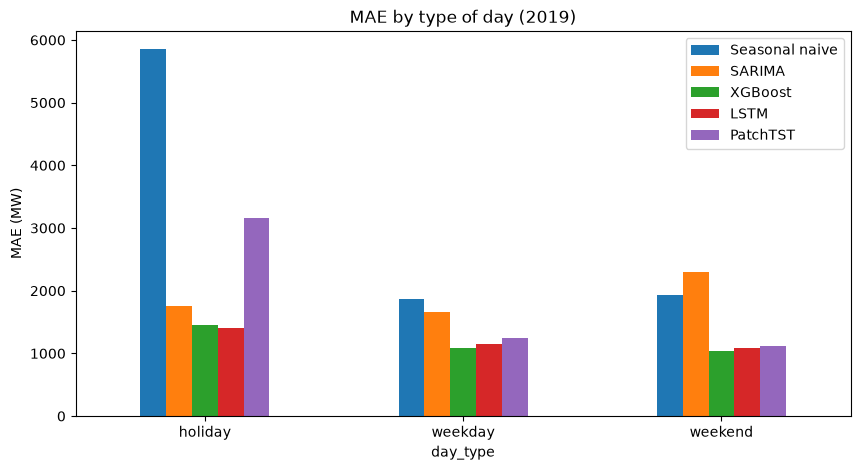

In [5]:
by_day_type.set_index("day_type")[models].plot.bar(figsize=(10, 5))
plt.title("MAE by type of day (2019)")
plt.ylabel("MAE (MW)")
plt.xticks(rotation=0)
plt.savefig(figures_folder + "/09_mae_by_day_type.png")
plt.show()

### 3. RQ3: Error at peak hours

In the EDA (notebook 03) demand was highest around 17:00-18:00 UK time. I call **16:00-19:59 UK time** the peak hours.

In [6]:
results["period"] = "off-peak"
results.loc[(results["hour"] >= 16) & (results["hour"] <= 19), "period"] = "peak"

by_period = mae_by_group("period")
by_period.to_csv(tables_folder + "/09_mae_by_period.csv", index=False)
by_period.round(0)

,period,hours,Seasonal naive,SARIMA,XGBoost,LSTM,PatchTST
0,off-peak,7244,1982.0,1819.0,1053.0,1138.0,1227.0
1,peak,1445,1953.0,1979.0,1213.0,1144.0,1341.0


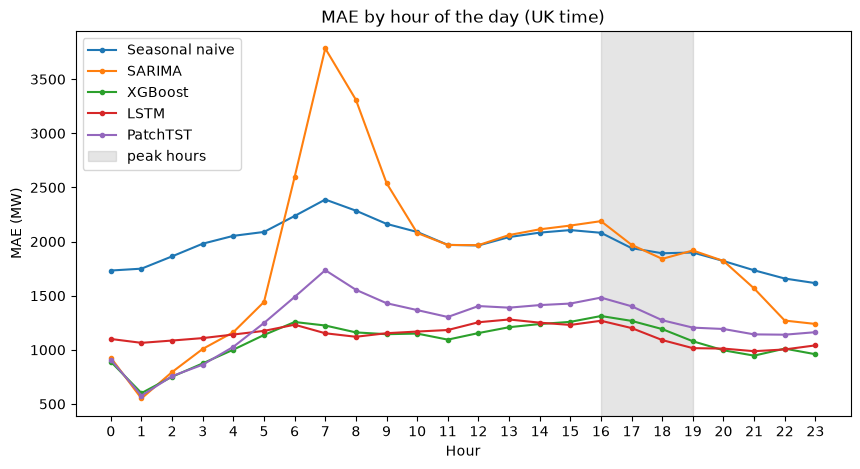

In [7]:
by_hour = mae_by_group("hour")

plt.figure(figsize=(10, 5))
for name in models:
    plt.plot(by_hour["hour"], by_hour[name], marker="o", markersize=3, label=name)
plt.axvspan(16, 19, color="grey", alpha=0.2, label="peak hours")
plt.title("MAE by hour of the day (UK time)")
plt.xlabel("Hour")
plt.ylabel("MAE (MW)")
plt.xticks(range(0, 24))
plt.legend()
plt.savefig(figures_folder + "/09_mae_by_hour.png")
plt.show()

### 4. Error by month

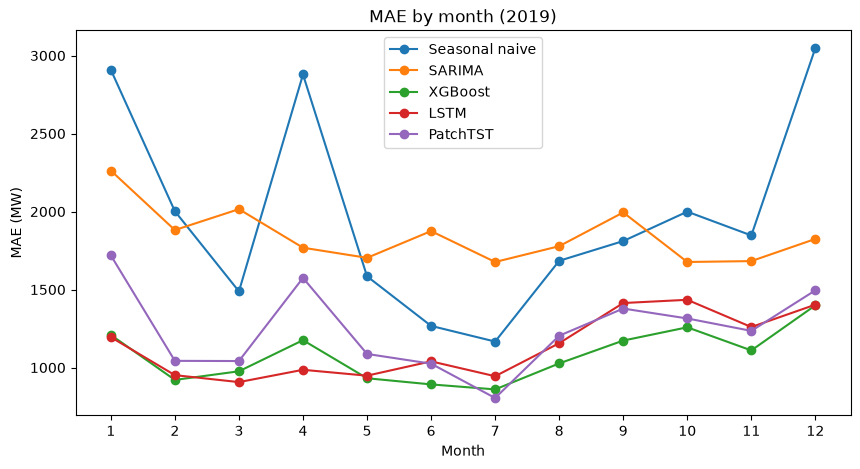

In [8]:
by_month = mae_by_group("month")
by_month.to_csv(tables_folder + "/09_mae_by_month.csv", index=False)

plt.figure(figsize=(10, 5))
for name in models:
    plt.plot(by_month["month"], by_month[name], marker="o", label=name)
plt.title("MAE by month (2019)")
plt.xlabel("Month")
plt.ylabel("MAE (MW)")
plt.xticks(range(1, 13))
plt.legend()
plt.savefig(figures_folder + "/09_mae_by_month.png")
plt.show()

### 5. The worst days

In [9]:
results["date"] = results["time"].dt.date

worst_rows = []
for date, part in results.groupby("date"):
    row = [date]
    for name in models:
        row.append(mae(part["actual"], part[name]))
    worst_rows.append(row)

by_date = pd.DataFrame(worst_rows, columns=["date"] + models)

# the 10 worst days for XGBoost
by_date.sort_values("XGBoost", ascending=False).head(10).round(0)

,date,Seasonal naive,SARIMA,XGBoost,LSTM,PatchTST
265,2019-09-23,2417.0,1477.0,3101.0,3080.0,2435.0
1,2019-01-02,6588.0,6515.0,3082.0,2278.0,5713.0
24,2019-01-25,3862.0,4798.0,2695.0,1488.0,2738.0
356,2019-12-23,3566.0,1025.0,2589.0,2806.0,2739.0
293,2019-10-21,2135.0,936.0,2532.0,2089.0,1579.0
117,2019-04-28,4274.0,1108.0,2354.0,772.0,2747.0
302,2019-10-30,1846.0,664.0,2348.0,2362.0,2210.0
123,2019-05-04,2100.0,5256.0,2313.0,1966.0,2227.0
309,2019-11-06,4608.0,2684.0,2237.0,1464.0,1936.0
0,2019-01-01,3795.0,1289.0,2237.0,1149.0,2129.0


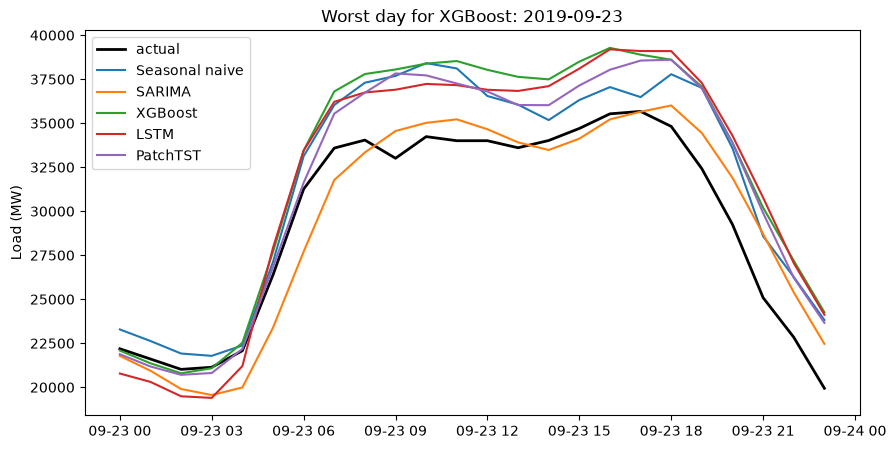

In [10]:
# the worst day for XGBoost, all models
worst_day = by_date.sort_values("XGBoost", ascending=False)["date"].iloc[0]
part = results[results["date"] == worst_day]

plt.figure(figsize=(10, 5))
plt.plot(part["time"], part["actual"], label="actual", color="black", linewidth=2)
for name in models:
    plt.plot(part["time"], part[name], label=name)
plt.title("Worst day for XGBoost: " + str(worst_day))
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/09_worst_day.png")
plt.show()

### 6. RQ4: Feature ablation

Does the model get better when I add calendar features and temperature? I train XGBoost and LSTM with four feature sets:

| Set | Features |
|---|---|
| A: history only | past load only (lags and rolling means for XGBoost, last 168 hours for LSTM) |
| B: + calendar | A + hour, day_of_week, month, is_weekend, is_holiday |
| C: + temperature | A + temperature |
| D: all | A + calendar + temperature |

**The ablation is done on the validation year 2018**, not on 2019, so the test year is only used once (for the final results in notebook 08).
Models are trained on data before 2018.

In [11]:
data = pd.read_csv("../datasets/processed/gb_features_2015_2019.csv")

df = pd.DataFrame()
df["unique_id"] = ["GB"] * len(data)
df["ds"] = pd.to_datetime(data["time"]).dt.tz_localize(None)
df["y"] = data["load"]

calendar = ["hour", "day_of_week", "month", "is_weekend", "is_holiday"]
weather = ["temperature"]
for col in calendar + weather:
    df[col] = data[col]

# only up to the end of 2018
until_2018 = df[df["ds"] < "2019-01-01"]

feature_sets = {
    "A: history only": [],
    "B: + calendar": calendar,
    "C: + temperature": weather,
    "D: all": calendar + weather,
}

#### XGBoost

In [12]:
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from xgboost import XGBRegressor

# use the best setting from notebook 06
tuning = pd.read_csv(tables_folder + "/xgboost_tuning.csv")
best = tuning.sort_values("MAE_2018").iloc[0]

xgb_results = []
for set_name, extra in feature_sets.items():
    columns = ["unique_id", "ds", "y"] + extra
    model = MLForecast(
        models={"XGBoost": XGBRegressor(n_estimators=500, max_depth=int(best["max_depth"]),
                                        learning_rate=best["learning_rate"], subsample=0.8,
                                        colsample_bytree=0.8, random_state=42)},
        freq="h",
        lags=[1, 24, 168],
        lag_transforms={1: [RollingMean(window_size=24), RollingMean(window_size=168)]},
    )
    cv = model.cross_validation(df=until_2018[columns], h=24, step_size=24, n_windows=365, refit=False, static_features=[])
    error = mae(cv["y"], cv["XGBoost"])
    xgb_results.append([set_name, error])
    print("XGBoost", set_name, "-> MAE", round(error))

XGBoost A: history only -> MAE 1569


XGBoost B: + calendar -> MAE 1054


XGBoost C: + temperature -> MAE 1484


XGBoost D: all -> MAE 980


#### LSTM
The LSTM uses 2017 for early stopping here, because 2018 is now the year being tested.

In [13]:
from neuralforecast import NeuralForecast
from neuralforecast.models import LSTM

warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

lstm_results = []
for set_name, extra in feature_sets.items():
    columns = ["unique_id", "ds", "y"] + extra
    lstm = LSTM(
        h=24, input_size=168, futr_exog_list=extra,
        max_steps=2000, val_check_steps=50, early_stop_patience_steps=5,
        scaler_type="standard", random_seed=1,
        enable_progress_bar=False, enable_model_summary=False, logger=False,
    )
    model = NeuralForecast(models=[lstm], freq="h")
    cv = model.cross_validation(df=until_2018[columns], n_windows=365, step_size=24, refit=False, val_size=8760)
    error = mae(cv["y"], cv["LSTM"])
    lstm_results.append([set_name, error])
    print("LSTM", set_name, "-> MAE", round(error))

Seed set to 1


Seed set to 1


LSTM A: history only -> MAE 1523


Seed set to 1


LSTM B: + calendar -> MAE 1090


Seed set to 1


LSTM C: + temperature -> MAE 1170


LSTM D: all -> MAE 1013


In [14]:
ablation = pd.DataFrame()
ablation["feature set"] = [row[0] for row in xgb_results]
ablation["XGBoost MAE"] = [row[1] for row in xgb_results]
ablation["LSTM MAE"] = [row[1] for row in lstm_results]

# improvement compared with set A
ablation["XGBoost change vs A (%)"] = (ablation["XGBoost MAE"] / ablation["XGBoost MAE"].iloc[0] - 1) * 100
ablation["LSTM change vs A (%)"] = (ablation["LSTM MAE"] / ablation["LSTM MAE"].iloc[0] - 1) * 100

ablation.to_csv(tables_folder + "/09_ablation.csv", index=False)
ablation.round(1)

,feature set,XGBoost MAE,LSTM MAE,XGBoost change vs A (%),LSTM change vs A (%)
0,A: history only,1569.0,1523.0,0.0,0.0
1,B: + calendar,1054.1,1089.6,-32.8,-28.5
2,C: + temperature,1483.8,1170.3,-5.4,-23.2
3,D: all,980.2,1013.3,-37.5,-33.5


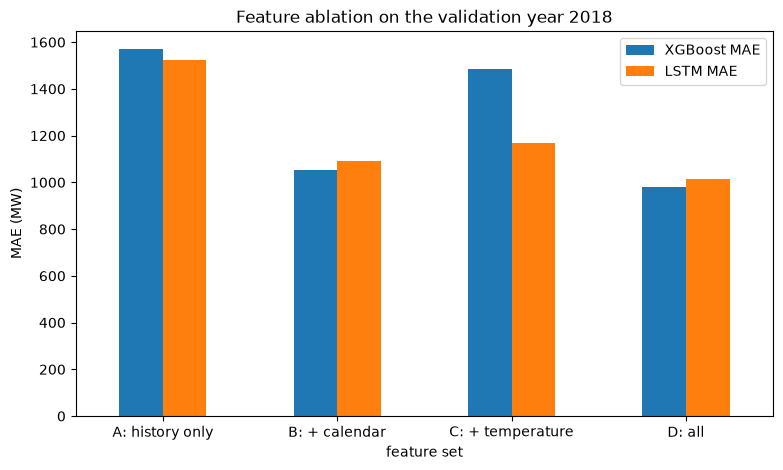

In [15]:
ablation.set_index("feature set")[["XGBoost MAE", "LSTM MAE"]].plot.bar(figsize=(9, 5))
plt.title("Feature ablation on the validation year 2018")
plt.ylabel("MAE (MW)")
plt.xticks(rotation=0)
plt.savefig(figures_folder + "/09_ablation.png")
plt.show()

### Summary

- **RQ3:** the tables above show the error on weekdays, weekends, holidays and at peak hours
- **RQ4:** the ablation table shows how much calendar features and temperature change the error
- All tables are saved in `results/tables/` and all figures in `results/figures/`